# Piloto en español: reutilización de continuaciones sintéticas

**IMAC — 9 de noviembre de 2026.** Este notebook es nuevo y autónomo: subir solo este archivo.

El usuario confirmó que la investigación debe medir texto en **español**. Se propone
`datificate/gpt2-small-spanish`, corpus `wikimedia/wikipedia` (`20231101.es`) y codificador
`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`. Son recursos del piloto,
pendientes de comprobar con esta ejecución, no una validación del protocolo final.

El modelo generador es un GPT-2 pequeño adaptado a español desde un checkpoint inglés,
según su ficha. Es un modelo de continuación, no un chat. El corpus también está en español;
no se traduce WikiText. El codificador semántico es multilingüe, apropiado para incluir español.

**Escala:** 64 ejemplos de entrenamiento, 32 de validación, dos ciclos, una repetición y
0/100 % de objetivos sintéticos. Cinco ajustes en total: M0 humano y dos por condición.
Los contextos de 64 tokens permanecen originales y los objetivos tienen 128 tokens.
Cada ajuste restaura el checkpoint base y crea un optimizador nuevo. La recursión se
transmite por datos, no mediante acumulación de pesos.

## Antes de ejecutar

1. Importar como notebook nuevo, conservando la copia anterior y sus salidas.
2. En Colab, **Entorno de ejecución → Reiniciar sesión** para limpiar imports interrumpidos.
   Seleccionar GPU en **Cambiar tipo de entorno de ejecución**. El código no compra recursos.
3. Ejecutar las celdas en orden. La primera instala bibliotecas y contiene todos los imports
   necesarios para ello. Si Colab pide reiniciar tras instalar, reiniciar y continuar con imports.
4. Descargar el ZIP al terminar: `/content` es temporal. No se monta Drive ni se requieren claves.

**Estado:** controles offline y sintaxis verificados; este nuevo notebook aún no se ejecutó
en Colab. Es un piloto de viabilidad, sin resultados finales ni promesa de duración.


## 1. Instalación

Python >=3.11, PyTorch >=2.6 preinstalado por Colab. Se fijan Transformers 5.22.2 y Datasets
5.1.0; Matplotlib dibuja gráficas y Safetensors permite guardar pesos sin objetos pickle.
Se registran nombres/versiones del entorno al ejecutar. No se reemplaza el PyTorch de Colab.


In [1]:
import sys
import subprocess
import importlib.util

if sys.version_info < (3, 11):
    raise RuntimeError("Usar un runtime reciente de Colab con Python >=3.11.")
if importlib.util.find_spec("torch") is None:
    raise RuntimeError("Falta PyTorch. Usar un entorno estándar de Colab con GPU.")
if any(name in sys.modules for name in ("transformers", "datasets")):
    raise RuntimeError("Reiniciar sesión para limpiar los imports anteriores antes de instalar.")
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--upgrade",
                "transformers==5.22.2", "datasets==5.1.0", "matplotlib>=3.9,<4",
                "safetensors>=0.6"], check=True)
print("Dependencias instaladas. Si Colab pide reiniciar, hacerlo antes de continuar.")


Dependencias instaladas. Si Colab pide reiniciar, hacerlo antes de continuar.


## 2. Controles del protocolo y del español

Se conservan tildes y ñ con normalización Unicode NFC. Se comprueban semillas, etiquetas,
mezclas exactas, longitudes comunes, separación por artículo y detección de duplicados.
Las etiquetas de contexto y relleno se excluyen de la pérdida mediante `-100`.
Las utilidades de WikiText del módulo anterior quedan como funciones auxiliares probadas,
pero no se usan para seleccionar el nuevo corpus: aquí cada registro ya es un artículo.


In [2]:
"""Controles del protocolo; solo biblioteca estándar, también embebidos en el notebook."""
import hashlib
import json
import math
import random
import re
from collections import Counter


def stable_seed(*parts):
    raw = json.dumps(parts, ensure_ascii=False, separators=(',', ':')).encode()
    return int.from_bytes(hashlib.sha256(raw).digest()[:4], 'big')


def articles(rows):
    """WikiText: solo un encabezado = título = inicia otro artículo.

    Se retiran encabezados de cualquier nivel; se conservan párrafos y saltos.
    Un fragmento inicial sin título se conserva como artículo propio.
    """
    out, body, title = [], [], 'untitled'
    for row in rows:
        text = row.strip()
        if re.match(r'^=\s+[^=].*?\s+=$', text):
            if body:
                out.append({'article': f'{len(out)}:{title}', 'text': '\n'.join(body)})
            body, title = [], text.strip('= ').strip()
        elif text and not re.match(r'^=+\s.*?\s=+$', text):
            body.append(text)
    if body:
        out.append({'article': f'{len(out)}:{title}', 'text': '\n'.join(body)})
    return out


def windows(docs, context_len, target_len, split):
    width = context_len + target_len
    out = []
    for doc in docs:
        for offset in range(0, len(doc['tokens']) - width + 1, width):
            block = doc['tokens'][offset:offset + width]
            out.append({'id': f"{split}:{doc['article']}:{offset}",
                        'split': split, 'article': doc['article'], 'offset': offset,
                        'context': block[:context_len], 'target': block[context_len:]})
    return out


def labelled(context, target, pad_id, length=None):
    if not context or not target:
        raise ValueError('Contexto y objetivo deben ser no vacíos.')
    ids = list(context) + list(target)
    length = len(ids) if length is None else length
    if length < len(ids):
        raise ValueError('El relleno no puede truncar el objetivo.')
    padding = length - len(ids)
    return (ids + [pad_id] * padding,
            [1] * len(ids) + [0] * padding,
            [-100] * len(context) + list(target) + [-100] * padding)


def mix_targets(human, synthetic, alpha, seed):
    """Reemplaza ejemplos completos; longitud fija implica proporción exacta de tokens."""
    if not human or not 0 <= alpha <= 1:
        raise ValueError('Corpus vacío o proporción inválida.')
    count = len(human) * alpha
    if not math.isclose(count, round(count)):
        raise ValueError('La proporción debe dar un número entero de ejemplos.')
    length = len(human[0]['target'])
    if any(len(x['target']) != length for x in human):
        raise ValueError('Objetivos humanos de longitud desigual.')
    if alpha and (synthetic is None or len(synthetic) != len(human)
                  or any(len(x) != length for x in synthetic)):
        raise ValueError('Objetivos sintéticos incompletos o de longitud desigual.')
    chosen = set(random.Random(seed).sample(range(len(human)), round(count)))
    return [dict(x, context=list(x['context']),
                 target=list(synthetic[i] if i in chosen else x['target']),
                 synthetic=i in chosen) for i, x in enumerate(human)]


WORD_PATTERN = r"\w+(?:['’]\w+)*"


def words(text):
    return re.findall(WORD_PATTERN, text.lower(), flags=re.UNICODE)


def lexical_metrics(texts, limit):
    if not texts or limit < 4:
        raise ValueError('Se requieren textos y al menos cuatro palabras por texto.')
    seqs = [words(t) for t in texts]
    short = sum(len(s) < limit for s in seqs)
    result = {'word_limit': limit, 'n_texts': len(texts), 'short_texts': short,
              'distinct_2': None, 'distinct_3': None, 'repeat_4_mean': None}
    if short:
        return result
    seqs = [s[:limit] for s in seqs]
    for n in (2, 3):
        grams = [tuple(s[i:i+n]) for s in seqs for i in range(len(s)-n+1)]
        result[f'distinct_{n}'] = len(set(grams)) / len(grams)
    repeats = []
    for s in seqs:
        grams = [tuple(s[i:i+4]) for i in range(len(s)-3)]
        repeats.append(1 - len(set(grams)) / len(grams))
    result['repeat_4_mean'] = sum(repeats) / len(repeats)
    return result


"""Selección de artículos del corpus español; sin librerías externas."""
import hashlib
import random
import unicodedata
base_words = words
base_lexical_metrics = lexical_metrics


def normalized_text(text):
    return unicodedata.normalize('NFC', text.replace('\r\n', '\n').replace('\r', '\n')).strip()


def words(text):
    return base_words(normalized_text(text))


def lexical_metrics(texts, limit):
    return base_lexical_metrics([normalized_text(t) for t in texts], limit)


def article_partition(article_id, seed):
    digest = hashlib.sha256(f'{seed}:article_split:{article_id}'.encode()).digest()
    bucket = int.from_bytes(digest[:8], 'big') % 100
    return 'train' if bucket < 80 else 'validation' if bucket < 90 else 'test'


def spanish_candidates(records, tokenize, context_len, target_len, seed, max_articles):
    """Prefijo acotado del streaming; una ventana aleatoria por artículo elegible.

    Las particiones son propias (80/10/10 aproximado por hash), no oficiales.
    Los artículos asignados a test no se tokenizan ni se usan para medir.
    El prefijo no es una muestra representativa de toda Wikipedia.
    """
    if context_len <= 0 or target_len <= 0 or max_articles <= 0:
        raise ValueError('Longitudes y límite de artículos deben ser positivos.')
    pools = {'train': [], 'validation': []}
    width = context_len + target_len
    audit = {'scanned_articles': 0, 'reserved_test_articles': 0,
             'too_short_articles': 0, 'duplicate_ids': 0}
    seen = set()
    for row in records:
        if audit['scanned_articles'] >= max_articles:
            break
        audit['scanned_articles'] += 1
        article = str(row['id'])
        if article in seen:
            audit['duplicate_ids'] += 1
            continue
        seen.add(article)
        split = article_partition(article, seed)
        if split == 'test':
            audit['reserved_test_articles'] += 1
            continue
        text = normalized_text(row['text'])
        tokens = tokenize(text)
        count = len(tokens) // width
        if not count:
            audit['too_short_articles'] += 1
            continue
        offset = random.Random(stable_seed(seed, 'window', article)).randrange(count) * width
        block = tokens[offset:offset + width]
        pools[split].append({'id': f'es:{split}:{article}:{offset}', 'split': split,
            'article': article, 'title': row.get('title', ''), 'url': row.get('url', ''),
            'offset': offset, 'text_sha256': hashlib.sha256(text.encode()).hexdigest(),
            'context': block[:context_len], 'target': block[context_len:]})
    return pools, audit


def select_spanish_rows(pools, train_count, valid_count, seed):
    selected = {}
    for split, count in (('train', train_count), ('validation', valid_count)):
        if len(pools[split]) < count:
            raise ValueError(f'{split}: solo {len(pools[split])} artículos elegibles; se necesitan {count}. '
                             'Revisar el límite antes de generar o entrenar.')
        selected[split] = random.Random(stable_seed(seed, 'data', split)).sample(pools[split], count)
    train_ids = {r['article'] for r in selected['train']}
    train_text = {r['text_sha256'] for r in selected['train']}
    if any(r['article'] in train_ids or r['text_sha256'] in train_text for r in selected['validation']):
        raise ValueError('Artículo o contenido idéntico entre entrenamiento y validación.')
    for split, rows in selected.items():
        if len({r['text_sha256'] for r in rows}) != len(rows):
            raise ValueError(f'Contenido duplicado en la muestra de {split}; revisar sin reemplazos silenciosos.')
    return selected


In [3]:
"""Controles offline: ejecutar con python -m unittest discover -s Experimentos -v."""
import unittest


class ProtocolTests(unittest.TestCase):
    def test_article_boundaries_and_subheadings(self):
        rows = [' = One = \n', 'alpha', ' == Sub == \n', 'beta', ' = Two = \n', 'gamma']
        docs = articles(rows)
        self.assertEqual(len(docs), 2)
        self.assertIn('beta', docs[0]['text'])
        self.assertNotIn('gamma', docs[0]['text'])
        self.assertNotIn('One', docs[0]['text'])

    def test_no_cross_article_or_overlapping_windows(self):
        docs = [{'article': 'a', 'tokens': list(range(13))},
                {'article': 'b', 'tokens': list(range(100, 105))}]
        blocks = windows(docs, 2, 3, 'train')
        self.assertEqual([x['offset'] for x in blocks], [0, 5, 0])
        self.assertEqual(blocks[1]['context'] + blocks[1]['target'], list(range(5, 10)))
        self.assertEqual(blocks[2]['target'], [102, 103, 104])
        self.assertEqual(len({x['id'] for x in blocks}), 3)

    def test_context_and_padding_are_not_training_targets(self):
        ids, mask, labels = labelled([8, 9], [10, 11, 12], pad_id=1, length=7)
        self.assertEqual(ids, [8, 9, 10, 11, 12, 1, 1])
        self.assertEqual(mask, [1, 1, 1, 1, 1, 0, 0])
        self.assertEqual(labels, [-100, -100, 10, 11, 12, -100, -100])

    def test_mixture_is_exact_and_keeps_human_context(self):
        human = [{'id': str(i), 'context': [i], 'target': [7, 7, 7, 7]} for i in range(4)]
        synthetic = [[9, 9, 9, 9] for _ in human]
        out = mix_targets(human, synthetic, .5, 42)
        self.assertEqual(sum(x['synthetic'] for x in out), 2)
        self.assertEqual(sum(x['target'].count(9) for x in out), 8)
        self.assertEqual([x['context'] for x in out], [[i] for i in range(4)])
        self.assertEqual(human[0]['target'], [7, 7, 7, 7])
        with self.assertRaises(ValueError):
            mix_targets(human, [[9]] * 4, 1, 42)
        with self.assertRaises(ValueError):
            mix_targets(human, synthetic, .3, 42)

    def test_seeds_stable_and_namespaces_separate(self):
        self.assertEqual(stable_seed(42, 'train', 1), stable_seed(42, 'train', 1))
        self.assertNotEqual(stable_seed(42, 'train', 1), stable_seed(42, 'eval', 1))

    def test_lexical_metrics_do_not_cross_text_boundaries(self):
        m = lexical_metrics(['A b a b a b', 'c d c d c d'], 6)
        self.assertAlmostEqual(m['distinct_2'], 4 / 10)
        self.assertAlmostEqual(m['repeat_4_mean'], 1 / 3)
        self.assertEqual(m['short_texts'], 0)

    def test_short_texts_are_not_silently_dropped(self):
        m = lexical_metrics(['a b c d', 'a'], 4)
        self.assertEqual(m['short_texts'], 1)
        self.assertIsNone(m['distinct_2'])
        self.assertIsNone(m['repeat_4_mean'])



"""Pruebas adicionales del piloto español, sin GPU ni descargas."""
import unittest


class SpanishProtocolTests(unittest.TestCase):
    def test_accents_and_enye_are_preserved(self):
        self.assertEqual(normalized_text('  cancio\u0301n\r\nniño  '), 'canción\nniño')
        self.assertEqual(words(normalized_text('Árbol, niño y acción.')), ['árbol', 'niño', 'y', 'acción'])
        self.assertEqual(words('cancio\u0301n y niño'), ['canción', 'y', 'niño'])
        self.assertEqual(lexical_metrics(['cancio\u0301n y niño feliz'], 4),
                         lexical_metrics(['canción y niño feliz'], 4))

    def test_partition_is_stable_and_uses_all_three_folds(self):
        folds = [article_partition(str(i), 42) for i in range(200)]
        self.assertEqual(set(folds), {'train', 'validation', 'test'})
        self.assertEqual(article_partition('15', 42), article_partition('15', 42))

    def test_article_stays_in_one_partition_and_only_one_window(self):
        rows = [{'id': str(i), 'title': f'Título {i}', 'url': 'https://es.wikipedia.org/',
                 'text': 'Texto en español con suficientes palabras.'} for i in range(70)]
        seen_texts = []
        def tokenize(text):
            seen_texts.append(text)
            return list(range(20))
        pools, audit = spanish_candidates(rows, tokenize, 2, 3, seed=42, max_articles=60)
        self.assertEqual(audit['scanned_articles'], 60)
        self.assertLess(len(seen_texts), 60)  # Los artículos de test no se tokenizan.
        all_rows = pools['train'] + pools['validation']
        self.assertEqual(len(all_rows), len({r['article'] for r in all_rows}))
        self.assertFalse(set(r['article'] for r in pools['train']) &
                         set(r['article'] for r in pools['validation']))
        for row in all_rows:
            self.assertEqual(len(row['context']), 2)
            self.assertEqual(len(row['target']), 3)
            self.assertEqual(row['split'], article_partition(row['article'], 42))
            self.assertEqual(row['offset'] % 5, 0)

    def test_short_articles_are_reported_without_padding(self):
        rows = [{'id': str(i), 'title': 'Corto', 'text': 'corto'} for i in range(40)]
        pools, audit = spanish_candidates(rows, lambda t: [1, 2], 2, 3, 42, 40)
        self.assertEqual(pools, {'train': [], 'validation': []})
        self.assertGreater(audit['too_short_articles'], 0)

    def test_duplicate_reference_text_across_folds_is_rejected(self):
        pools = {'train': [{'article': 'a', 'text_sha256': 'same'}],
                 'validation': [{'article': 'b', 'text_sha256': 'same'}]}
        with self.assertRaises(ValueError):
            select_spanish_rows(pools, 1, 1, 42)

    def test_sample_counts_are_exact_and_pool_must_suffice(self):
        pools = {s: [{'article': f'{s}{i}', 'text_sha256': f'{s}{i}'} for i in range(10)]
                 for s in ('train', 'validation')}
        selected = select_spanish_rows(pools, 4, 3, 42)
        self.assertEqual(len(selected['train']), 4)
        self.assertEqual(len(selected['validation']), 3)
        self.assertEqual(selected, select_spanish_rows(pools, 4, 3, 42))
        with self.assertRaises(ValueError):
            select_spanish_rows(pools, 11, 3, 42)



suite = unittest.TestSuite([
    unittest.defaultTestLoader.loadTestsFromTestCase(ProtocolTests),
    unittest.defaultTestLoader.loadTestsFromTestCase(SpanishProtocolTests),
])
report = unittest.TextTestRunner(verbosity=2).run(suite)
assert report.wasSuccessful(), "No continuar si falla algún control."


test_article_boundaries_and_subheadings (__main__.ProtocolTests.test_article_boundaries_and_subheadings) ... ok
test_context_and_padding_are_not_training_targets (__main__.ProtocolTests.test_context_and_padding_are_not_training_targets) ... ok
test_lexical_metrics_do_not_cross_text_boundaries (__main__.ProtocolTests.test_lexical_metrics_do_not_cross_text_boundaries) ... ok
test_mixture_is_exact_and_keeps_human_context (__main__.ProtocolTests.test_mixture_is_exact_and_keeps_human_context) ... ok
test_no_cross_article_or_overlapping_windows (__main__.ProtocolTests.test_no_cross_article_or_overlapping_windows) ... ok
test_seeds_stable_and_namespaces_separate (__main__.ProtocolTests.test_seeds_stable_and_namespaces_separate) ... ok
test_short_texts_are_not_silently_dropped (__main__.ProtocolTests.test_short_texts_are_not_silently_dropped) ... ok
test_accents_and_enye_are_preserved (__main__.SpanishProtocolTests.test_accents_and_enye_are_preserved) ... ok
test_article_stays_in_one_partition

## 3. Imports y configuración

Configuración acotada al piloto. Ajuste completo en float32, una época, AdamW con tasa
2e-5, betas .9/.999, epsilon 1e-8 y weight decay .01 en todos los parámetros, clipping 1,
sin scheduler. Lote efectivo 8, microbatch 2: ocho actualizaciones por ajuste.

GPU obligatoria por defecto. `allow_cpu=True` permite CPU deliberadamente, sin tiempos
comprobados. `save_checkpoints=False` evita varios GB: se guardan datos, parámetros,
semillas y resultados. Puede activarse antes de ejecutar si se desean también los pesos.


In [4]:
import csv
import importlib.metadata
import os
import platform
import shutil
import sys
import time
import uuid
from contextlib import contextmanager
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path

# No se necesitan tokens para estos repositorios públicos.
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN'] = '1'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from datasets import load_dataset
from huggingface_hub import HfApi
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM, GPT2Config, GPT2LMHeadModel
import matplotlib.pyplot as plt


@dataclass(frozen=True)
class Config:
    language: str = 'es'
    model: str = 'datificate/gpt2-small-spanish'
    dataset: str = 'wikimedia/wikipedia'
    subset: str = '20231101.es'
    embedding: str = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'
    article_pool: int = 2000
    seed: int = 20261109
    train_examples: int = 64
    eval_examples: int = 32
    context_tokens: int = 64
    target_tokens: int = 128
    cycles: int = 2
    alphas: tuple = (0.0, 1.0)
    micro_batch: int = 2
    effective_batch: int = 8
    sample_batch: int = 8
    learning_rate: float = 2e-5
    betas: tuple = (0.9, 0.999)
    epsilon: float = 1e-8
    weight_decay: float = 0.01
    max_grad_norm: float = 1.0
    temperature: float = 1.0
    top_p: float = 0.95
    max_words: int = 32
    embedding_max_tokens: int = 128
    allow_cpu: bool = False
    save_checkpoints: bool = False


CFG = Config()


def validate_config(cfg):
    if cfg.language != 'es' or cfg.subset != '20231101.es':
        raise ValueError('Este piloto debe trabajar con el corpus en español.')
    if (cfg.train_examples != 64 or cfg.eval_examples != 32 or cfg.cycles != 2
            or tuple(cfg.alphas) != (0.0, 1.0)):
        raise ValueError('Este notebook está acotado al piloto; no activar el estudio final aquí.')
    if cfg.train_examples % cfg.effective_batch or cfg.effective_batch % cfg.micro_batch:
        raise ValueError('Los lotes deben dividir el corpus y el lote efectivo exactamente.')
    if not 0 < cfg.top_p <= 1 or cfg.temperature <= 0:
        raise ValueError('Parámetros de muestreo inválidos.')


def seed_training(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def weight_hash(model):
    digest = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        digest.update(name.encode())
        digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


def cpu_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def reset_for_fit(model, base_state, expected_hash, cfg, seed):
    model.load_state_dict(base_state, strict=True)
    model.zero_grad(set_to_none=True)
    observed_hash = weight_hash(model)
    if observed_hash != expected_hash:
        raise RuntimeError('La inicialización no coincide con el modelo base.')
    seed_training(seed)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=cfg.learning_rate, betas=cfg.betas,
        eps=cfg.epsilon, weight_decay=cfg.weight_decay, foreach=False)
    if len(optimizer.state):
        raise RuntimeError('El optimizador no empieza vacío.')
    return optimizer, observed_hash


def batch_tensors(rows, pad_id, device):
    packed = [labelled(x['context'], x['target'], pad_id) for x in rows]
    return {name: torch.tensor([x[i] for x in packed], dtype=torch.long, device=device)
            for i, name in enumerate(('input_ids', 'attention_mask', 'labels'))}


def fit_one(model, base_state, base_hash, rows, cfg, seed, device, pad_id):
    optimizer, initial_hash = reset_for_fit(model, base_state, base_hash, cfg, seed)
    generator = torch.Generator().manual_seed(stable_seed(seed, 'shuffle'))
    loader = DataLoader(rows, batch_size=cfg.micro_batch, shuffle=True,
                        generator=generator, collate_fn=list, num_workers=0)
    accumulation = cfg.effective_batch // cfg.micro_batch
    model.train()
    losses, updates, seen = [], 0, 0
    for step, batch in enumerate(loader, start=1):
        data = batch_tensors(batch, pad_id, device)
        labels = data['labels']
        assert (labels[:, :cfg.context_tokens] == -100).all().item()
        assert (labels[:, cfg.context_tokens:] != -100).sum().item() == len(batch) * cfg.target_tokens
        output = model(**data, use_cache=False)
        if not torch.isfinite(output.loss).item():
            raise RuntimeError('Pérdida no finita; no se cambian parámetros automáticamente.')
        losses.append(float(output.loss.detach().cpu()))
        (output.loss / accumulation).backward()
        seen += len(batch) * cfg.target_tokens
        if step % accumulation == 0:
            norm = torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.max_grad_norm)
            if not torch.isfinite(norm).item():
                raise RuntimeError('Gradiente no finito.')
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            updates += 1
    assert updates == len(rows) // cfg.effective_batch
    assert seen == len(rows) * cfg.target_tokens
    del optimizer
    model.eval()
    return {'initial_weight_sha256': initial_hash, 'train_seed': seed,
            'optimizer_initial_entries': 0, 'updates': updates,
            'target_tokens_seen': seen, 'train_loss_mean': sum(losses)/len(losses),
            'final_weight_sha256': weight_hash(model)}


## 4. Generación y comprobaciones PyTorch

Temperatura 1, top-p .95, sin top-k ni penalización de repetición. Un generador independiente
por solicitud; evaluación con semillas pareadas entre etapas y separadas de generación de
datos y entrenamiento. Se producen 128 tokens, excluyendo todos los IDs especiales,
incluido EOS. Es una política propuesta de longitud fija que modifica la distribución de
decodificación y debe documentarse; no se filtra por calidad.

Antes de descargar los recursos grandes, un GPT-2 diminuto de pesos aleatorios comprueba
pérdida causal, relleno, caché, reproducibilidad y restauración de pesos/optimizador.
No requiere descargas y no constituye un resultado del experimento.


In [5]:
def nucleus_draw(logits, generators, cfg, forbidden_ids):
    logits = logits.float().clone() / cfg.temperature
    logits[:, forbidden_ids] = -float('inf')
    values, indices = torch.sort(logits, descending=True, dim=-1)
    probs = torch.softmax(values, dim=-1)
    remove = (torch.cumsum(probs, dim=-1) - probs) >= cfg.top_p
    values[remove] = -float('inf')
    probs = torch.softmax(values, dim=-1)
    draws = [torch.multinomial(p, 1, generator=g) for p, g in zip(probs, generators)]
    return indices.gather(1, torch.stack(draws))


@torch.inference_mode()
def sample_targets(model, rows, cfg, device, forbidden_ids, namespace, progress=True):
    """Un RNG por solicitud; no se hereda el RNG de entrenamiento.

    Política piloto: longitud fija y ningún token especial (incluye EOS/PAD/BOS).
    Se conserva el token que cruza el umbral top-p. Sin top-k ni penalizaciones.
    """
    model.eval()
    targets, seeds = [], []
    for start in range(0, len(rows), cfg.sample_batch):
        batch = rows[start:start+cfg.sample_batch]
        batch_seeds = [stable_seed(cfg.seed, 'sampling', namespace, x['id']) for x in batch]
        generators = [torch.Generator(device=device).manual_seed(s) for s in batch_seeds]
        ids = torch.tensor([x['context'] for x in batch], dtype=torch.long, device=device)
        generated, cache = [], None
        attention = torch.ones_like(ids)
        for _ in range(cfg.target_tokens):
            output = model(input_ids=ids, attention_mask=attention,
                           past_key_values=cache, use_cache=True)
            ids = nucleus_draw(output.logits[:, -1, :], generators, cfg, forbidden_ids)
            generated.append(ids)
            cache = output.past_key_values
            attention = torch.cat([attention, torch.ones_like(ids)], dim=1)
        result = torch.cat(generated, dim=1).cpu().tolist()
        assert all(len(x) == cfg.target_tokens for x in result)
        assert all(not (set(x) & set(forbidden_ids)) for x in result)
        targets.extend(result)
        seeds.extend(batch_seeds)
        if progress:
            print(f'  Muestreo {min(start+cfg.sample_batch, len(rows))}/{len(rows)}', flush=True)
    return targets, seeds


def torch_smoke_checks():
    """Sin descargas: GPT-2 diminuto; pérdida causal, caché, semillas y reinicio."""
    from dataclasses import replace
    seed_training(17)
    toy = GPT2LMHeadModel(GPT2Config(vocab_size=32, n_embd=16, n_inner=32,
        n_layer=1, n_head=2, n_positions=32,
        resid_pdrop=0.0, embd_pdrop=0.0, attn_pdrop=0.0,
        pad_token_id=1, bos_token_id=2, eos_token_id=2)).cpu()
    config = replace(CFG, context_tokens=2, target_tokens=4,
                     micro_batch=1, effective_batch=2, sample_batch=2)
    rows = [{'id': str(i), 'context': [4, 5], 'target': [6, 7, 8, 9]} for i in range(2)]
    data = batch_tensors(rows, 1, 'cpu')
    toy.eval()
    output = toy(**data, use_cache=False)
    manual = F.cross_entropy(output.logits[:, :-1, :].reshape(-1, 32),
                             data['labels'][:, 1:].reshape(-1), ignore_index=-100)
    assert torch.allclose(output.loss, manual, atol=1e-6)
    assert data['labels'][:, 1:].ne(-100).sum().item() == 8
    a, _ = sample_targets(toy, rows, config, 'cpu', [0, 1, 2, 3], 'check', False)
    torch.rand(123)  # Perturbar RNG global no debe cambiar la generación.
    b, _ = sample_targets(toy, rows, config, 'cpu', [0, 1, 2, 3], 'check', False)
    assert a == b
    base, signature = cpu_state(toy), weight_hash(toy)
    fit_one(toy, base, signature, rows, config, 99, 'cpu', 1)
    assert weight_hash(toy) != signature
    optimizer, observed = reset_for_fit(toy, base, signature, config, 99)
    assert observed == signature and len(optimizer.state) == 0
    # El relleno debe estar excluido también después del desplazamiento causal.
    ids, mask, labels = labelled([4, 5], [6, 7], 1, 7)
    padded = {k: torch.tensor([v]) for k, v in
              zip(('input_ids', 'attention_mask', 'labels'), (ids, mask, labels))}
    toy.eval()
    output = toy(**padded, use_cache=False)
    loss = F.cross_entropy(output.logits[:, :-1].reshape(-1, 32),
                           padded['labels'][:, 1:].reshape(-1), ignore_index=-100)
    assert torch.allclose(output.loss, loss, atol=1e-6)
    del optimizer, toy
    print('Controles PyTorch: pérdida causal, relleno, muestreo y reinicio correctos.')


## 5. Corpus español y particiones propias

Wikipedia ofrece `20231101.es` con una sola partición oficial `train`. **No se inventan
particiones oficiales:** se asigna cada artículo por SHA-256 de semilla e ID a train,
validación o reserva de prueba (80/10/10 aproximado). Se aplica streaming a un prefijo
de hasta 2000 artículos, para limitar la preparación; ese prefijo no es una muestra
representativa de toda Wikipedia. El streaming puede descargar buffers adicionales.

Los artículos reservados para prueba se omiten antes de tokenizar. De cada artículo
elegible se elige una sola ventana entre sus bloques no solapados de 64+128 tokens, con
semilla fija; después se muestrean 64 artículos para entrenamiento y 32 para validación.
No se mezclan artículos entre particiones. Se verifican duplicados por ID, hash del texto
completo y ventanas exactas. Si faltan candidatos o hay duplicados, se detiene sin reemplazos
silenciosos. Se guardan revisión, IDs, URLs, hashes, offsets, conteos y regla de selección.

**Límite de procedencia:** Wikipedia se usa como referencia original; no acredita autoría
humana individual ni ausencia de contenido sintético. El modelo ya fue adaptado a Wikipedia
en español; separar artículos en este piloto no demuestra ausencia de solapamiento con su
preentrenamiento. La PPL es una referencia relativa de dominio, no evidencia de conocimiento nuevo.

Se usan revisiones registradas, `trust_remote_code=False` y recursos públicos sin claves.
Safetensors cuando está disponible; para los pesos `.bin` del GPT-2 se exige
`weights_only=True` con PyTorch >=2.6. Cada ejecución crea otra carpeta; sin reanudación
automática. Los errores conservan archivos parciales.


In [6]:
def write_json(path, obj):
    path = Path(path)
    temp = path.with_suffix(path.suffix + '.tmp')
    temp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temp.replace(path)


def write_jsonl(path, rows):
    with Path(path).open('w', encoding='utf-8') as stream:
        for row in rows:
            stream.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + '\n')


def hash_json(obj):
    return hashlib.sha256(json.dumps(obj, ensure_ascii=False, sort_keys=True).encode()).hexdigest()


class Clock:
    def __init__(self, path, device):
        self.path, self.device, self.records = path, device, []

    @contextmanager
    def measure(self, stage, **tags):
        if self.device == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        status = 'error'
        try:
            yield
            status = 'ok'
        finally:
            if self.device == 'cuda':
                torch.cuda.synchronize()
            self.records.append(dict(stage=stage, seconds=time.perf_counter()-start,
                                     status=status, **tags))
            write_json(self.path, self.records)


def select_data(cfg, tokenizer, revision):
    # El repositorio solo tiene train: nuestras particiones se definen por artículo.
    # Streaming evita descargar toda la Wikipedia; puede transferir buffers adicionales.
    raw = load_dataset(cfg.dataset, cfg.subset, split='train', revision=revision,
                       streaming=True, token=False)
    def tokenize(text):
        return tokenizer(text, add_special_tokens=False, truncation=False,
                         verbose=False)['input_ids']
    pools, audit = spanish_candidates(raw, tokenize, cfg.context_tokens, cfg.target_tokens,
                                      cfg.seed, cfg.article_pool)
    print('Artículos examinados:', audit['scanned_articles'],
          '| Candidatos:', {k: len(v) for k, v in pools.items()}, flush=True)
    selected = select_spanish_rows(pools, cfg.train_examples, cfg.eval_examples, cfg.seed)
    fingerprints = {'selection': audit, 'official_split': 'train',
        'partition_policy': 'SHA256(seed:article_split:id) mod100; train<80, validation<90, test>=90',
        'sampling_scope': f'Prefijo de hasta {cfg.article_pool} artículos; una ventana por artículo',
        'test_tokenized_or_evaluated': False,
        'normalization': 'NFC y saltos de línea; se conservan tildes y ñ',
        'provenance': 'Referencia Wikipedia; no se acredita autoría humana individual'}
    for split, chosen in selected.items():
        fingerprints[split] = {'available_articles': len(pools[split]),
                              'selected_sha256': hash_json(chosen)}
    # Comprobar también igualdad exacta de las ventanas seleccionadas entre particiones.
    train_blocks = {tuple(x['context'] + x['target']) for x in selected['train']}
    if any(tuple(x['context'] + x['target']) in train_blocks for x in selected['validation']):
        raise RuntimeError('Hay bloques idénticos seleccionados entre train y validation; revisar corpus.')
    return selected, fingerprints


## 6. Métricas para los textos en español

- **Perplejidad:** sobre las 128 posiciones objetivo originales de validación; se excluye
  el contexto, incluyendo correctamente la primera predicción de continuación.
- **Distinct-2/3:** proporción de n-gramas únicos del corpus, sin cruzar textos.
- **Repetición de 4-gramas:** promedio por texto de `1 - únicos/total`.
- **Dispersión semántica:** promedio de `1 - coseno` entre pares, con MiniLM multilingüe,
  mean pooling con máscara y normalización L2; es un indicador de dispersión, no de calidad.

Se conservan tildes y ñ. El conteo usa palabras/números Unicode en minúsculas, sin stemming
ni eliminación de palabras vacías. Se fija W con las referencias de validación: mínimo
entre 32 y la longitud de su continuación más corta. Métricas léxicas/semánticas usan las
primeras W palabras. Si una salida no alcanza W, se registra y las métricas de esa etapa
quedan ausentes, sin descartar textos ni rellenarlos. PPL sigue calculándose.

MiniLM multilingüe usa un límite de 128 wordpieces, coherente con su configuración; se
informa cualquier truncamiento. Un modelo generador español no garantiza que cada salida
sea español fluido: se guardan las muestras para revisarlas, sin filtrar por idioma o calidad.


In [7]:
@torch.inference_mode()
def human_perplexity(model, rows, cfg, device, pad_id):
    model.eval()
    nll, count = 0.0, 0
    for start in range(0, len(rows), cfg.micro_batch):
        batch = batch_tensors(rows[start:start+cfg.micro_batch], pad_id, device)
        output = model(input_ids=batch['input_ids'], attention_mask=batch['attention_mask'], use_cache=False)
        labels = batch['labels'][:, 1:].contiguous()
        loss = F.cross_entropy(output.logits[:, :-1, :].float().reshape(-1, output.logits.size(-1)),
                               labels.reshape(-1), reduction='sum', ignore_index=-100)
        nll += float(loss.cpu())
        count += int(labels.ne(-100).sum().item())
    assert count == len(rows) * cfg.target_tokens
    mean = nll / count
    if not math.isfinite(mean) or mean > 700:
        raise RuntimeError('Perplejidad no finita o fuera de rango.')
    return {'human_nll': mean, 'human_perplexity': math.exp(mean), 'ppl_target_tokens': count}


@torch.inference_mode()
def semantic_dispersion(texts, encoder, encoder_tokenizer, cfg, limit):
    # Mismas primeras W palabras que en diversidad léxica; sin descartar textos cortos.
    if any(len(words(t)) < limit for t in texts):
        return {'semantic_dispersion': None, 'embedding_truncated_texts': None}
    embeddings, truncated = [], 0
    encoder.eval()
    for start in range(0, len(texts), 16):
        batch = [' '.join(words(t)[:limit]) for t in texts[start:start+16]]
        lengths = [len(x) for x in encoder_tokenizer(batch, truncation=False)['input_ids']]
        truncated += sum(n > cfg.embedding_max_tokens for n in lengths)
        inputs = encoder_tokenizer(batch, padding=True, truncation=True,
                                   max_length=cfg.embedding_max_tokens, return_tensors='pt')
        output = encoder(**inputs).last_hidden_state
        mask = inputs['attention_mask'].unsqueeze(-1).to(output.dtype)
        pooled = (output * mask).sum(1) / mask.sum(1).clamp_min(1)
        embeddings.append(F.normalize(pooled, p=2, dim=1))
    matrix = torch.cat(embeddings)
    similarity = matrix @ matrix.T
    upper = torch.triu_indices(len(texts), len(texts), offset=1)
    dispersion = 1 - similarity[upper[0], upper[1]].mean().item()
    return {'semantic_dispersion': dispersion, 'embedding_truncated_texts': truncated}


def evaluate_stage(model, valid, tokenizer, encoder, enc_tokenizer, cfg,
                   device, forbidden, limit, folder, clock):
    with clock.measure('eval_generation', stage_id=folder.name):
        generated, seeds = sample_targets(model, valid, cfg, device, forbidden, 'validation_paired')
    texts = tokenizer.batch_decode(generated, skip_special_tokens=True)
    with clock.measure('eval_perplexity', stage_id=folder.name):
        metrics = human_perplexity(model, valid, cfg, device, tokenizer.pad_token_id)
    metrics.update(lexical_metrics(texts, limit))
    with clock.measure('eval_embeddings', stage_id=folder.name):
        metrics.update(semantic_dispersion(texts, encoder, enc_tokenizer, cfg, limit))
    with clock.measure('write_outputs', stage_id=folder.name):
        write_jsonl(folder/'validation_generations.jsonl', [
            {'id': row['id'], 'seed': seed, 'target_ids': ids, 'text': text}
            for row, seed, ids, text in zip(valid, seeds, generated, texts)])
        write_json(folder/'metrics.json', metrics)
    return metrics


## 7. Ejecutar el piloto en español

La celda siguiente define el procedimiento y la posterior lo ejecuta. Son cinco ajustes:
M0 y dos ciclos en cada condición. M0 se comparte y cada ajuste vuelve a los pesos base.
El control conserva objetivos originales; al 100 % solo las continuaciones se sustituyen
por texto del modelo anterior. Los contextos siguen siendo originales.

Se guardan datos y resultados incrementalmente. Se cronometran carga, ajuste, generación
de corpus, generación de evaluación, perplejidad, embeddings y escritura por separado.


In [8]:
def run_pilot(cfg=CFG):
    validate_config(cfg)
    if sys.version_info < (3, 11):
        raise RuntimeError('Se requiere Python 3.11 o posterior.')
    major_minor = tuple(int(n) for n in torch.__version__.split('+')[0].split('.')[:2])
    if major_minor < (2, 6):
        raise RuntimeError('Se requiere PyTorch >=2.6. Usar un runtime reciente de Colab.')
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print('PyTorch:', torch.__version__, '| Dispositivo:', device, flush=True)
    if device == 'cpu' and not cfg.allow_cpu:
        raise RuntimeError('No hay GPU CUDA. Elegir GPU en Colab y ejecutar desde el principio. '
                           'Para CPU deliberada, cambiar allow_cpu=True; no se promete duración.')
    torch.use_deterministic_algorithms(True)
    if device == 'cuda':
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False
        torch.backends.cudnn.benchmark = False
        print('GPU:', torch.cuda.get_device_name(0), flush=True)
    torch_smoke_checks()
    root = Path('/content/imac_piloto_es') if Path('/content').is_dir() else Path.cwd()/'salidas_piloto_es'
    run = root/(datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:8])
    run.mkdir(parents=True, exist_ok=False)
    clock = Clock(run/'timings.json', device)
    # Solo nombres/versiones; no pip freeze con posibles URLs privadas o credenciales.
    versions = dict(sorted((dist.metadata['Name'], dist.version)
                           for dist in importlib.metadata.distributions()
                           if dist.metadata.get('Name')))
    manifest = {'status': 'running', 'kind': 'spanish_pilot_not_final_results', 'config': asdict(cfg),
                'python': platform.python_version(), 'versions': versions, 'device': device,
                'started_utc': datetime.now(timezone.utc).isoformat(), 'test_used': False,
                'gpu': torch.cuda.get_device_name(0) if device == 'cuda' else None,
                'gpu_bytes': torch.cuda.get_device_properties(0).total_memory if device == 'cuda' else None,
                'eos_policy': '128 tokens; todos los IDs especiales excluidos; sin rechazo ni filtrado',
                'seed_policy': 'SHA256; entrenamiento separado; evaluación pareada entre etapas',
                'optimizer': 'AdamW; una época; sin scheduler; decay uniforme en parámetros',
                'precision': 'float32; sin AMP ni TF32; determinismo estricto en este entorno',
                'checkpoints_saved': cfg.save_checkpoints,
                'resume_policy': 'no reanudación automática; cada ejecución crea otra carpeta'}
    write_json(run/'manifest.json', manifest)
    print('Directorio de salida:', run, flush=True)
    try:
        api = HfApi(token=False)
        with clock.measure('resolve_revisions'):
            model_info = api.model_info(cfg.model)
            dataset_info = api.dataset_info(cfg.dataset)
            embed_info = api.model_info(cfg.embedding)
            revisions = {'model': model_info.sha, 'dataset': dataset_info.sha, 'embedding': embed_info.sha}
            safe_model = any(x.rfilename.endswith('.safetensors') for x in model_info.siblings)
        manifest.update(revisions=revisions, model_uses_safetensors=safe_model)
        write_json(run/'manifest.json', manifest)
        with clock.measure('load_tokenizer_data'):
            tokenizer = AutoTokenizer.from_pretrained(cfg.model, revision=revisions['model'],
                                                      trust_remote_code=False, token=False)
            if tokenizer.pad_token_id is None:
                if tokenizer.eos_token_id is None:
                    raise RuntimeError('El tokenizador no define PAD ni EOS para usar como relleno.')
                tokenizer.pad_token = tokenizer.eos_token  # No añade vocabulario ni pesos nuevos.
            selected, fingerprints = select_data(cfg, tokenizer, revisions['dataset'])
            human, valid = selected['train'], selected['validation']
            references = tokenizer.batch_decode([r['target'] for r in valid], skip_special_tokens=True)
            limit = min(cfg.max_words, min(len(words(t)) for t in references))
            if limit < 4:
                raise RuntimeError('La referencia no permite un límite léxico común >=4; revisar antes de continuar.')
            manifest.update(data=fingerprints, word_limit=limit, word_regex=WORD_PATTERN,
                            forbidden_generation_ids=tokenizer.all_special_ids)
            write_json(run/'manifest.json', manifest)
            write_jsonl(run/'train_human.jsonl', human)
            write_jsonl(run/'validation_human.jsonl', valid)
        with clock.measure('load_model'):
            model = AutoModelForCausalLM.from_pretrained(cfg.model, revision=revisions['model'],
                trust_remote_code=False, token=False, use_safetensors=safe_model,
                weights_only=True, dtype=torch.float32, attn_implementation='eager').to(device)
            model.config.pad_token_id = tokenizer.pad_token_id
            if max(tokenizer.all_special_ids) >= model.get_input_embeddings().num_embeddings:
                raise RuntimeError('Los tokens especiales no corresponden al vocabulario del modelo.')
            if not all(p.requires_grad for p in model.parameters()):
                raise RuntimeError('No están habilitados todos los parámetros.')
            base = cpu_state(model)
            base_hash = weight_hash(model)
            manifest['base_weight_sha256'] = base_hash
            manifest['parameters'] = sum(p.numel() for p in model.parameters())
            write_json(run/'manifest.json', manifest)
        with clock.measure('load_embeddings'):
            enc_tokenizer = AutoTokenizer.from_pretrained(cfg.embedding, revision=revisions['embedding'],
                                                          trust_remote_code=False, token=False)
            encoder = AutoModel.from_pretrained(cfg.embedding, revision=revisions['embedding'],
                trust_remote_code=False, token=False, use_safetensors=True,
                dtype=torch.float32).cpu().eval()
        with clock.measure('reference_embeddings'):
            reference_metrics = lexical_metrics(references, limit)
            reference_metrics.update(semantic_dispersion(references, encoder, enc_tokenizer, cfg, limit))
        write_json(run/'human_reference_metrics.json', reference_metrics)
        results = []

        def stage(name, rows, cycle, alpha):
            folder = run/name
            folder.mkdir(exist_ok=False)
            write_jsonl(folder/'training_corpus.jsonl', rows)
            # Misma semilla de ajuste para ambas proporciones en el mismo ciclo.
            seed = stable_seed(cfg.seed, 'fit', 'replicate_0', cycle)
            with clock.measure('fit', stage_id=name):
                fit_record = fit_one(model, base, base_hash, rows, cfg, seed, device, tokenizer.pad_token_id)
            write_json(folder/'fit.json', fit_record)
            if cfg.save_checkpoints:
                with clock.measure('save_checkpoint', stage_id=name):
                    model.save_pretrained(folder/'checkpoint', safe_serialization=True)
                    tokenizer.save_pretrained(folder/'checkpoint')
            metrics = evaluate_stage(model, valid, tokenizer, encoder, enc_tokenizer, cfg,
                device, tokenizer.all_special_ids, limit, folder, clock)
            results.append(dict(stage=name, cycle=cycle, alpha=alpha, **metrics))
            write_json(run/'results.json', results)
            with (run/'results.csv').open('w', newline='', encoding='utf-8') as stream:
                writer = csv.DictWriter(stream, fieldnames=list(results[0]))
                writer.writeheader()
                writer.writerows(results)
            print(f'{name}: PPL={metrics["human_perplexity"]:.3f}; '
                  f'Distinct-2={metrics["distinct_2"]}; cortos={metrics["short_texts"]}', flush=True)

        stage('M0_human', human, 0, None)
        initial = cpu_state(model)
        for alpha in cfg.alphas:
            model.load_state_dict(initial, strict=True)
            for cycle in range(1, cfg.cycles+1):
                name = f'alpha_{int(alpha*100):03d}_g{cycle}'
                synthetic, sample_seeds = None, []
                if alpha:
                    with clock.measure('train_generation', stage_id=name):
                        synthetic, sample_seeds = sample_targets(model, human, cfg, device,
                            tokenizer.all_special_ids, f'train_alpha_{alpha}_cycle_{cycle}')
                    write_jsonl(run/f'{name}_synthetic.jsonl', [
                        {'id': x['id'], 'seed': s, 'target_ids': ids}
                        for x, s, ids in zip(human, sample_seeds, synthetic)])
                mixture_seed = stable_seed(cfg.seed, 'mixture', alpha, cycle)
                rows = mix_targets(human, synthetic, alpha, mixture_seed)
                assert sum(x['synthetic'] for x in rows) * cfg.target_tokens == int(alpha * len(rows) * cfg.target_tokens)
                stage(name, rows, cycle, alpha)
        assert len(results) == 5
        manifest.update(status='complete', finished_utc=datetime.now(timezone.utc).isoformat(),
                        fit_count=len(results), test_used=False)
        write_json(run/'manifest.json', manifest)
        print('Piloto terminado. Son controles de viabilidad, no resultados del estudio final.', flush=True)
        return run, results
    except Exception as error:
        # No volcar variables de entorno, credenciales ni encabezados de red.
        manifest.update(status='interrupted_or_failed', error_type=type(error).__name__)
        write_json(run/'manifest.json', manifest)
        print('Ejecución detenida; se conservan archivos parciales en', run, flush=True)
        raise


In [9]:
RUN_DIR, RESULTS = run_pilot(CFG)


PyTorch: 2.14.1+cu130 | Dispositivo: cuda
GPU: Tesla T4


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Controles PyTorch: pérdida causal, relleno, muestreo y reinicio correctos.
Directorio de salida: /content/imac_piloto_es/20261110T022838Z_1db7b1f0


config.json:   0%|          | 0.00/817 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/620 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/850k [00:00<?, ?B/s]

... (15 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  Muestreo 8/32
  Muestreo 16/32
  Muestreo 24/32
  Muestreo 32/32
M0_human: PPL=29.468; Distinct-2=0.9213709677419355; cortos=0
  Muestreo 8/32
  Muestreo 16/32
  Muestreo 24/32
  Muestreo 32/32
alpha_000_g1: PPL=29.101; Distinct-2=0.9375; cortos=0
  Muestreo 8/32
  Muestreo 16/32
  Muestreo 24/32
  Muestreo 32/32
alpha_000_g2: PPL=29.415; Distinct-2=0.9264112903225806; cortos=0
  Muestreo 8/64
  Muestreo 16/64
  Muestreo 24/64
  Muestreo 32/64
  Muestreo 40/64
  Muestreo 48/64
  Muestreo 56/64
  Muestreo 64/64
  Muestreo 8/32
  Muestreo 16/32
  Muestreo 24/32
  Muestreo 32/32
alpha_100_g1: PPL=30.430; Distinct-2=0.9203629032258065; cortos=0
  Muestreo 8/64
  Muestreo 16/64
  Muestreo 24/64
  Muestreo 32/64
  Muestreo 40/64
  Muestreo 48/64
  Muestreo 56/64
  Muestreo 64/64
  Muestreo 8/32
  Muestreo 16/32
  Muestreo 24/32
  Muestreo 32/32
alpha_100_g2: PPL=31.901; Distinct-2=0.9233870967741935; cortos=0
Piloto terminado. Son controles de viabilidad, no resultados del estudio final.


## 8. Gráficas y descarga

Se muestran trayectorias descriptivas de una sola repetición por condición. No se calculan
p-valores ni se identifica colapso únicamente por las gráficas. El ZIP incluye manifiesto,
corpus, salidas de validación, métricas, semillas, tiempos, CSV y figura. Los checkpoints
solo se incluyen si se activaron previamente. Descargar antes de cerrar Colab.


In [10]:
def summarize_pilot(run, results):
    columns = ['distinct_2', 'distinct_3', 'repeat_4_mean', 'semantic_dispersion', 'human_perplexity']
    fig, axes = plt.subplots(1, len(columns), figsize=(19, 3.6))
    for ax, metric in zip(axes, columns):
        for alpha in CFG.alphas:
            points = [results[0]] + [r for r in results[1:] if r['alpha'] == alpha]
            ys = [r[metric] if r[metric] is not None else float('nan') for r in points]
            ax.plot([r['cycle'] for r in points], ys, marker='o', label=f'{alpha:.0%}')
        ax.set_title(metric)
        ax.set_xlabel('Ciclo')
        ax.set_xticks([0, 1, 2])
        ax.grid(alpha=.3)
    axes[0].legend(title='Objetivos sintéticos')
    fig.suptitle('Piloto: una cadena por condición; sin inferencia estadística')
    fig.tight_layout()
    fig.savefig(run/'pilot_metrics.png', dpi=160, bbox_inches='tight')
    plt.show()
    times = json.loads((run/'timings.json').read_text(encoding='utf-8'))
    print('\nTiempos observados (segundos):')
    totals = Counter()
    for record in times:
        totals[record['stage']] += record['seconds']
    for name, seconds in totals.items():
        print(f'  {name}: {seconds:.1f}')
    print('No extrapolar solo desde ajuste: incluir generación, evaluación, carga y guardado.')
    print('Revisar los tiempos antes de decidir la escala final de 48 ajustes.')
    archive = shutil.make_archive(str(run)+'_resultados', 'zip', root_dir=run)
    print('Paquete:', archive)
    return archive


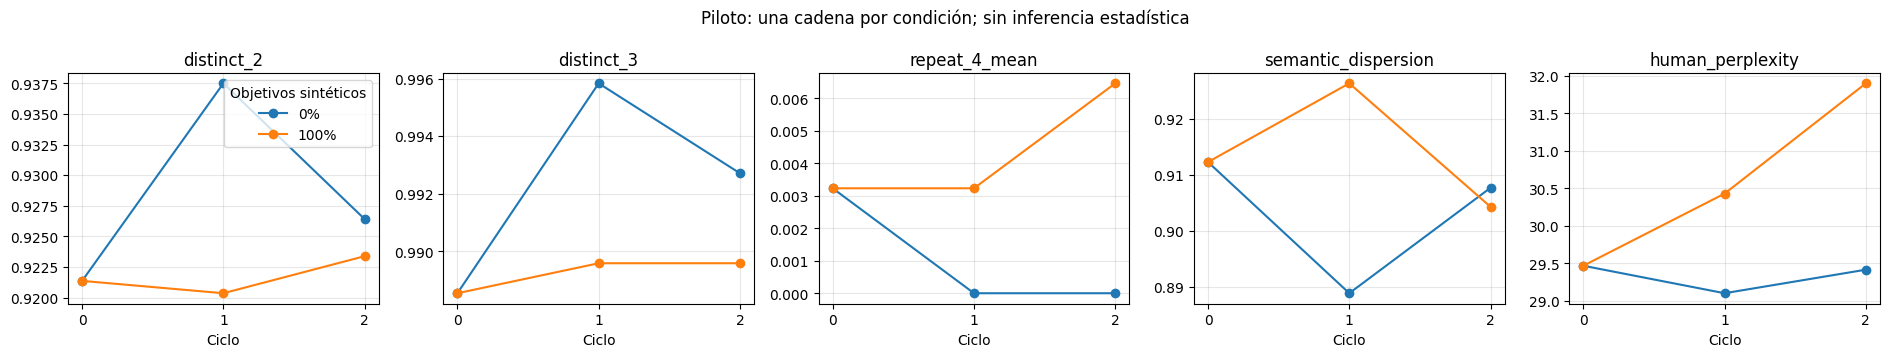


Tiempos observados (segundos):
  resolve_revisions: 0.4
  load_tokenizer_data: 56.2
  load_model: 11.2
  load_embeddings: 8.0
  reference_embeddings: 1.1
  fit: 49.7
  eval_generation: 45.4
  eval_perplexity: 3.3
  eval_embeddings: 4.3
  write_outputs: 0.0
  train_generation: 31.3
No extrapolar solo desde ajuste: incluir generación, evaluación, carga y guardado.
Revisar los tiempos antes de decidir la escala final de 48 ajustes.
Paquete: /content/imac_piloto_es/20261110T022838Z_1db7b1f0_resultados.zip


In [11]:
ARCHIVE = summarize_pilot(RUN_DIR, RESULTS)


In [12]:
try:
    from google.colab import files
except ImportError:
    print("El paquete está en", ARCHIVE)
else:
    files.download(ARCHIVE)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Comprobación final y fuentes

`manifest.json` debe indicar `status: complete`, `fit_count: 5`, `test_used: false` y
`config.language: es`. Cada ajuste debe tener ocho actualizaciones, 8192 tokens objetivo
y la misma huella de pesos iniciales. Revisar textos cortos, truncamientos y ejemplos.
Las semillas facilitan repetir la ejecución, pero no garantizan identidad numérica entre
hardware/versiones. Si un kernel no admite el determinismo estricto, registrar el error.

Guardar este notebook ejecutado y el ZIP. Revisar tiempos antes de decidir escala final;
no se inicia automáticamente el estudio de 48 ajustes. El piloto no se mezcla con sus resultados.

Fuentes primarias consultadas el **9 de noviembre de 2026**:

- [GPT-2 pequeño adaptado al español: ficha y procedencia](https://huggingface.co/datificate/gpt2-small-spanish).
- [Archivos del modelo, configuración y pesos](https://huggingface.co/datificate/gpt2-small-spanish/tree/main).
- [Wikipedia: configuración española y licencias](https://huggingface.co/datasets/wikimedia/wikipedia).
- [Codificador multilingüe](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2).
- [Límite del codificador: 128 tokens](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/blob/main/sentence_bert_config.json).
- [Streaming de Datasets](https://huggingface.co/docs/datasets/stream).

La ficha del generador y del codificador indican Apache-2.0; Wikipedia declara CC-BY-SA-3.0
y GFDL. Conservar atribución y condiciones correspondientes al usar o redistribuir recursos.
Este archivo contiene código; pesos y corpus se descargan solo al ejecutar. Las referencias
del artículo no se modificaron durante la preparación de esta nueva entrega.
